# 06 Map tour: the 3D map and how it is built

A static website (no server code, no external services at view time): Bronx and Brooklyn residential buildings as extruded footprints at their real roof height, coloured by one of five neutral layers, with a snapshot slider, filters, a click panel and a disclaimer.
Run it with `make map && make serve` (see [`docs/map.md`](../docs/map.md)). The images here are screenshots taken from the running page.

![Predicted risk, Brooklyn](../docs/img/map_risk_3d.jpg)

| | |
|---|---|
| ![panel](../docs/img/map_building_panel.jpg) | ![gap](../docs/img/map_complaint_gap.jpg) |
| Click panel | Complaint gap layer |
| ![dark](../docs/img/map_dark_districts.jpg) | ![filter](../docs/img/map_filter_top_gap.jpg) |
| District overview, dark mode | Top-decile filter |

The five layers: predicted risk of an enforcement event; predicted condition (no complaint information); the complaint gap; the share of closed complaints with no inspector access; observed complaints per unit.
**Read the gap layer with the Phase 4 verdict in mind: top-decile-gap buildings are not at hidden extra risk** (notebook 04).

In [1]:
from nbutil import *
import json
WEB = ROOT / "app" / "web" / "data"
meta = json.loads((WEB / "meta.json").read_text())
print({k: v for k, v in meta.items() if k != "snapshots"}); print("snapshots:", meta["snapshots"][0], "to", meta["snapshots"][-1], f"({len(meta['snapshots'])})")

{'sample_cd': '202', 'scored_buildings': 120705, 'context_buildings': 313630, 'lots': 101442, 'built': '2026-11-14T15:56:46'}
snapshots: 2022-01-01 to 2025-10-01 (16)


## The default view is aggregate: district averages

The map opens zoomed out on 30 community-district averages (approximate shapes unioned from footprints) so the first impression is not building by building.

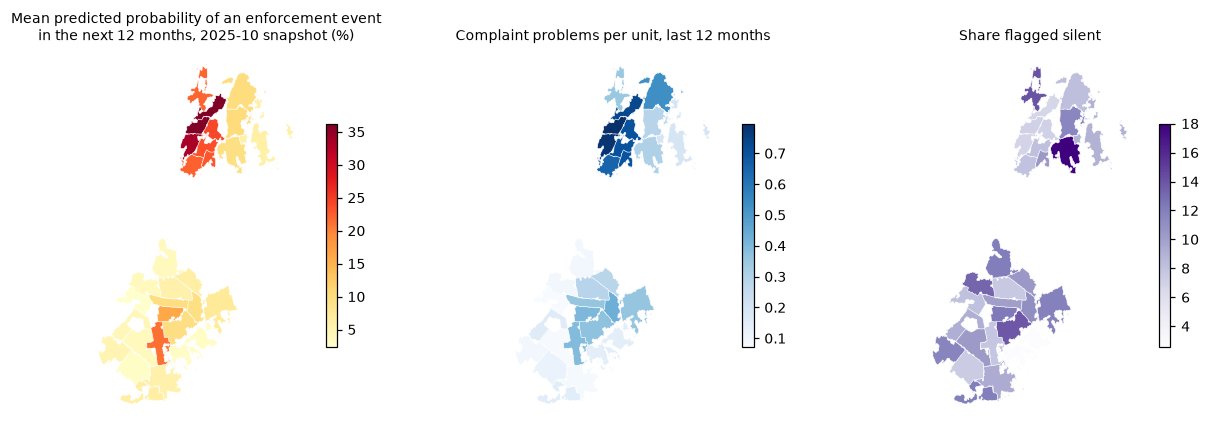

In [2]:
from matplotlib.patches import Polygon
from matplotlib.collections import PatchCollection
import numpy as np
dj = json.loads((WEB / "districts.json").read_text())
def draw(ax, key, title, cmap, scale=1.0):
    patches, vals = [], []
    for f in dj["features"]:
        geom = f["geometry"]; polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for poly in polys:
            ring = np.array(poly[0])
            ring[:, 0] = ring[:, 0] * np.cos(np.radians(40.7))
            patches.append(Polygon(ring, closed=True)); vals.append(f["properties"]["v"][key][-1] * scale)
    pc = PatchCollection(patches, cmap=cmap, edgecolor="white", linewidth=0.4); pc.set_array(np.array(vals)); ax.add_collection(pc)
    ax.autoscale_view(); ax.set_aspect("equal"); ax.axis("off"); ax.set_title(title, fontsize=9); plt.colorbar(pc, ax=ax, shrink=0.6)
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
draw(axes[0], "risk", "Mean predicted probability of an enforcement event\nin the next 12 months, 2025-10 snapshot (%)", "YlOrRd", 100)
draw(axes[1], "comp", "Complaint problems per unit, last 12 months", "Blues")
draw(axes[2], "silent", "Share flagged silent", "Purples", 100)
plt.tight_layout(); plt.show()

## How the slider avoids reloading data

Each score series is a string of 16 three-digit numbers (one per out-of-time snapshot, 999 = no value). Moving the slider only slices a string inside a MapLibre expression, so nothing is refetched; 80 numbers per building as separate tile properties would have been too heavy. A demonstration on the committed sample:

In [3]:
try:
    g = json.loads((WEB / "sample" / "buildings.geojson").read_text())
    f = g["features"][0]["properties"]
    s = f["r"]; k = len(meta["snapshots"])
    series = [int(s[3 * i:3 * i + 3]) for i in range(k)]
    print("raw string length:", len(s), "-> 16 values, one per snapshot")
    print(dict(zip(meta["snapshots"], [None if v == 999 else v for v in series])))
except FileNotFoundError:
    print("sample not present in this checkout")

raw string length: 48 -> 16 values, one per snapshot
{'2022-01-01': 458, '2022-04-01': 351, '2022-07-01': 380, '2022-10-01': 390, '2023-01-01': 615, '2023-04-01': 612, '2023-07-01': 714, '2023-10-01': 710, '2024-01-01': 776, '2024-04-01': 774, '2024-07-01': 759, '2024-10-01': 760, '2025-01-01': 796, '2025-04-01': 792, '2025-07-01': 794, '2025-10-01': 796}


## One community district, drawn from the committed sample

The sample is one community district (Bronx CD 202) as plain GeoJSON so the page works without the 93 MB tile file. Footprints are coloured by the predicted-risk percentile at the latest snapshot (the tiles store percentiles within each snapshot; the district view above shows mean probabilities).
(*Publication note: the sample contains per-building model scores; see `docs/PUBLISH_CHECKLIST.md` before making the repository public.*)

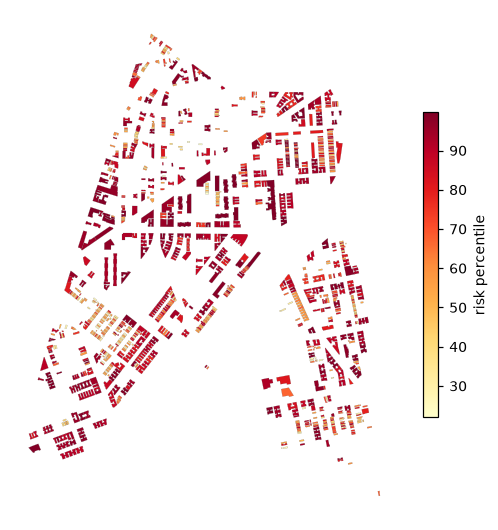

In [4]:
try:
    patches, vals = [], []
    for f in g["features"]:
        pr = f["properties"]
        v = int(pr["r"][-3:])
        if v == 999: continue
        geom = f["geometry"]; polys = geom["coordinates"] if geom["type"] == "MultiPolygon" else [geom["coordinates"]]
        for poly in polys:
            ring = np.array(poly[0]); ring[:, 0] = ring[:, 0] * np.cos(np.radians(40.85))
            patches.append(Polygon(ring, closed=True)); vals.append(v / 10)
    fig, ax = plt.subplots(figsize=(6, 6))
    pc = PatchCollection(patches, cmap="YlOrRd", linewidth=0.1, edgecolor="#555"); pc.set_array(np.array(vals)); ax.add_collection(pc)
    ax.autoscale_view(); ax.set_aspect("equal"); ax.axis("off"); plt.colorbar(pc, shrink=0.6, label="risk percentile"); plt.show()
except NameError:
    pass

## Privacy and limits
No owner names, tenant information or contacts anywhere in the tiles, shards or page; per-building shards and tiles are gitignored. Footprints inherit the scores of their lot; 471 scored lots have no footprint; district shapes are approximate; only the 16 out-of-time snapshots exist.
